# Personal Finance AI Agent using LangChain
**GenAI / Agentic AI**

## Objective
The aim is to build a small assistant that answers everyday money questions: what will my SIP be worth, what is the EMI on a loan, how much should I save every month for a goal, and how should I split my income. The important part is *how* it answers. The language model is not allowed to do the arithmetic itself. It has to read the question, pick a tool, pass the right numbers to it and then explain the result.

## What the notebook covers
1. Environment and API key
2. Core finance formulas (plain Python) and a check of those formulas
3. LangChain tools: calculator, EMI, SIP, goal-based SIP and 50-30-20 budget planner
4. The agent: LLM, system prompt and tool selection
5. Five required test queries, plus the four example questions from the project brief
6. Charts for SIP growth, loan amortisation and budget split
7. Streamlit front end

Every code cell has a heading above it and an explanation of the output below it.

## 1. Environment setup
Checking which versions of the libraries are installed so the results can be reproduced later.

In [1]:
import os
import sys
import importlib.metadata as md

for pkg in ["langchain", "langchain-core", "langchain-openai", "langgraph", "streamlit"]:
    print(f"{pkg:<18}{md.version(pkg)}")
print("Python          ", sys.version.split()[0])

langchain         1.4.7
langchain-core    1.7.0
langchain-openai  1.7.2
langgraph         1.2.16
streamlit         1.66.1
Python           3.12.0


#### Explanation
The cell prints the version of each package used in the project. LangChain 1.x is the version this notebook was written against, and it matters because the agent is created with `langchain.agents.create_agent`, which does not exist in the older 0.x releases. `langgraph` shows up because `create_agent` runs the tool-calling loop on top of it. If something fails on another machine, comparing these numbers is the first thing to do.

## 2. Loading the API key
The project brief suggests an OpenAI model (GPT-4o-mini). This run uses Google Gemini instead. LangChain makes that a one-function change (`get_llm()` in section 10) and nothing else in the project depends on which model sits behind the agent. The key is never typed into the notebook. It is read from `.streamlit/secrets.toml` (the same file Streamlit uses, so one file serves both the notebook and the app) or, if that file is missing, from the `GOOGLE_API_KEY` or `OPENAI_API_KEY` environment variable.

In [2]:
import tomllib
from pathlib import Path

secrets_file = Path(".streamlit/secrets.toml")
if secrets_file.exists():
    secrets = tomllib.loads(secrets_file.read_text())
    for name in ("GOOGLE_API_KEY", "OPENAI_API_KEY"):
        if secrets.get(name):
            os.environ[name] = secrets[name]      # the file wins over any old value in the environment

os.environ.pop("GEMINI_API_KEY", None)            # avoids Google's "both keys are set" ambiguity

print("secrets.toml present:", secrets_file.exists())
print("Google key found    :", bool(os.getenv("GOOGLE_API_KEY")))
print("OpenAI key found    :", bool(os.getenv("OPENAI_API_KEY")))

secrets.toml present: True
Google key found    : True
OpenAI key found    : False


#### Explanation
The cell loads the keys into the environment without printing them and only reports whether the file and each key were found. Values from `secrets.toml` replace any old key left in the environment, so the notebook cannot quietly use a stale one. `GEMINI_API_KEY` is removed because Google's library warns when it and `GOOGLE_API_KEY` are both set, and the key is passed to the model explicitly in section 10 anyway. If no key is found at all, the agent falls back to a small offline test model (section 9) so that the rest of the notebook still runs.

## 3. Core finance functions
All the maths goes into one plain Python file, `finance_core.py`. It has the EMI formula, the SIP future value formula, the same SIP formula turned around for goal planning, the 50-30-20 split, a safe expression evaluator for the calculator tool and an Indian-style currency formatter.

In [3]:
%%writefile finance_core.py
"""
finance_core.py
Plain Python maths for the personal finance agent.
No LangChain in here on purpose, so every formula can be tested on its own.
"""
import ast
import operator


# ---------- formatting ----------
def inr(amount, decimals=2):
    """Format a number in Indian digit grouping, e.g. 1234567.5 -> ₹12,34,567.50"""
    sign = "-" if amount < 0 else ""
    whole, _, frac = f"{abs(amount):.{decimals}f}".partition(".")
    if len(whole) > 3:
        head, tail = whole[:-3], whole[-3:]
        parts = []
        while len(head) > 2:
            parts.insert(0, head[-2:])
            head = head[:-2]
        if head:
            parts.insert(0, head)
        whole = ",".join(parts + [tail])
    return f"{sign}₹{whole}" + (f".{frac}" if decimals else "")


# ---------- input checks ----------
def _check(value, name, allow_zero=False):
    if value < 0 or (value == 0 and not allow_zero):
        raise ValueError(f"{name} must be {'zero or ' if allow_zero else ''}greater than zero (got {value})")


def monthly_rate(annual_percent):
    """Annual percentage -> monthly decimal rate (12% -> 0.01)."""
    return annual_percent / 12 / 100


# ---------- the formulas from the assignment brief ----------
def emi(principal, annual_rate, years):
    """EMI = P * r * (1+r)^n / ((1+r)^n - 1)"""
    _check(principal, "Loan amount")
    _check(annual_rate, "Interest rate", allow_zero=True)
    _check(years, "Tenure")
    n = round(years * 12)
    r = monthly_rate(annual_rate)
    if r == 0:                      # interest free loan, formula would divide by zero
        return principal / n
    growth = (1 + r) ** n
    return principal * r * growth / (growth - 1)


def sip_future_value(monthly_amount, annual_rate, years):
    """FV = P * ((1+r)^n - 1) / r   (instalment paid at the end of each month)"""
    _check(monthly_amount, "Monthly investment")
    _check(annual_rate, "Expected return", allow_zero=True)
    _check(years, "Investment period")
    n = round(years * 12)
    r = monthly_rate(annual_rate)
    if r == 0:
        return monthly_amount * n
    return monthly_amount * ((1 + r) ** n - 1) / r


def required_monthly_saving(target, annual_rate, years):
    """The SIP formula turned around: P = FV * r / ((1+r)^n - 1)"""
    _check(target, "Target amount")
    _check(annual_rate, "Expected return", allow_zero=True)
    _check(years, "Time horizon")
    n = round(years * 12)
    r = monthly_rate(annual_rate)
    if r == 0:
        return target / n
    return target * r / ((1 + r) ** n - 1)


def budget_split(income):
    """50-30-20 rule."""
    _check(income, "Monthly income")
    return {"Needs": income * 0.50, "Wants": income * 0.30, "Savings": income * 0.20}


# ---------- calculator ----------
_OPS = {
    ast.Add: operator.add, ast.Sub: operator.sub, ast.Mult: operator.mul,
    ast.Div: operator.truediv, ast.Pow: operator.pow, ast.Mod: operator.mod,
    ast.FloorDiv: operator.floordiv,
}


def safe_eval(expression):
    """
    Evaluate an arithmetic expression without using eval().
    Only numbers, + - * / // % ** and brackets are accepted.
    """
    cleaned = (expression.replace(",", "").replace("₹", "").replace("×", "*")
               .replace("÷", "/").replace("^", "**").strip())
    tree = ast.parse(cleaned, mode="eval")

    def walk(node):
        if isinstance(node, ast.Expression):
            return walk(node.body)
        if isinstance(node, ast.Constant) and isinstance(node.value, (int, float)):
            return node.value
        if isinstance(node, ast.BinOp) and type(node.op) in _OPS:
            left, right = walk(node.left), walk(node.right)
            if isinstance(node.op, ast.Pow) and abs(right) > 1000:
                raise ValueError("Exponent too large")
            return _OPS[type(node.op)](left, right)
        if isinstance(node, ast.UnaryOp) and isinstance(node.op, (ast.UAdd, ast.USub)):
            value = walk(node.operand)
            return value if isinstance(node.op, ast.UAdd) else -value
        raise ValueError("Only plain arithmetic is allowed")

    return walk(tree)

Overwriting finance_core.py


#### Explanation
The output line only confirms that the file was written. The file itself is what matters, and a few choices in it are worth explaining.

- **Formulas as in the brief.** `emi()` is `P·r·(1+r)^n / ((1+r)^n − 1)` and `sip_future_value()` is `P·((1+r)^n − 1)/r`, with `r` as the annual rate divided by 12 and 100, and `n` as years times 12.
- **Reverse SIP.** `required_monthly_saving()` solves the SIP formula for `P`. It is needed for the question "how much should I save monthly to reach ₹20 lakh", which the four required tools do not cover.
- **Zero interest.** Both formulas divide by the rate somewhere, so a rate of 0 would crash. The functions handle it separately.
- **Input checks.** Negative or zero amounts raise a clear `ValueError` which the tools later turn into a readable message.
- **`safe_eval`.** Python's `eval()` would run any code an LLM or user typed into the calculator. This function parses the text into a syntax tree and only allows numbers and arithmetic operators, so anything else is rejected.
- **Why no LangChain here.** Keeping the formulas separate lets me test them without an LLM, which is what the next section does.

## 4. Checking the formulas against numpy-financial
Before building tools on top of these functions, the results are compared with `numpy_financial`, a library that implements the same loan and annuity maths. If both agree, the formulas are typed correctly.

In [4]:
import pandas as pd
import numpy_financial as npf
from finance_core import emi, sip_future_value, required_monthly_saving

checks = {
    "EMI: 10 lakh, 9%, 20 yrs":   (emi(1_000_000, 9, 20),  -npf.pmt(0.09 / 12, 240, 1_000_000)),
    "EMI: 10 lakh, 8%, 20 yrs":   (emi(1_000_000, 8, 20),  -npf.pmt(0.08 / 12, 240, 1_000_000)),
    "SIP: 5000, 12%, 10 yrs":     (sip_future_value(5000, 12, 10), npf.fv(0.12 / 12, 120, -5000, 0)),
    "SIP: 7000, 10%, 15 yrs":     (sip_future_value(7000, 10, 15), npf.fv(0.10 / 12, 180, -7000, 0)),
    "SIP: 3000, 8%, 5 yrs":       (sip_future_value(3000, 8, 5),   npf.fv(0.08 / 12, 60, -3000, 0)),
}

table = pd.DataFrame(
    [{"case": k, "our formula": round(a, 2), "numpy-financial": round(b, 2), "difference": abs(a - b)}
     for k, (a, b) in checks.items()]
)
print(table.to_string(index=False))

# round trip: the saving needed for 20 lakh, invested again, should give back 20 lakh
p = required_monthly_saving(2_000_000, 12, 10)
print("\nMonthly saving for 20 lakh in 10 yrs at 12%:", round(p, 2))
print("Future value of that saving                :", round(sip_future_value(p, 12, 10), 2))

                    case  our formula  numpy-financial   difference
EMI: 10 lakh, 9%, 20 yrs      8997.26          8997.26 1.818989e-12
EMI: 10 lakh, 8%, 20 yrs      8364.40          8364.40 0.000000e+00
  SIP: 5000, 12%, 10 yrs   1150193.45       1150193.45 0.000000e+00
  SIP: 7000, 10%, 15 yrs   2901292.42       2901292.42 0.000000e+00
    SIP: 3000, 8%, 5 yrs    220430.57        220430.57 2.910383e-11

Monthly saving for 20 lakh in 10 yrs at 12%: 8694.19
Future value of that saving                : 2000000.0


#### Explanation
The table lists five cases, three SIPs and two EMIs, with our result next to the library's result. The values match to the paisa and the difference column is either exactly zero or a floating point residue of the order of 1e-11. That is expected because both sides use the same closed-form formulas, so this check is mostly protecting against typing mistakes such as a wrong bracket or using `years` instead of `months`.

The last two lines are a round trip. The reverse formula says ₹8,694.19 a month is needed for ₹20 lakh in 10 years at 12%. Feeding that amount back into the forward SIP formula returns ₹20,00,000, so the two functions are consistent with each other.

## 5. Edge cases: zero interest, bad input and unsafe expressions
Money tools get strange input, so a few awkward cases are tried directly on the functions.

In [5]:
from finance_core import safe_eval

print("EMI at 0% interest (10 lakh, 20 yrs):", round(emi(1_000_000, 0, 20), 2))

try:
    emi(-500_000, 9, 10)
except ValueError as err:
    print("Negative loan ->", err)

for expr in ["0.20 * 85000", "(1200 + 800) / 4", "2 ** 10", "__import__('os').system('ls')", "1 / 0"]:
    try:
        print(f"{expr!r:<34} -> {safe_eval(expr)}")
    except Exception as err:
        print(f"{expr!r:<34} -> rejected ({type(err).__name__}: {err})")

EMI at 0% interest (10 lakh, 20 yrs): 4166.67
Negative loan -> Loan amount must be greater than zero (got -500000)
'0.20 * 85000'                     -> 17000.0
'(1200 + 800) / 4'                 -> 500.0
'2 ** 10'                          -> 1024
"__import__('os').system('ls')"    -> rejected (ValueError: Only plain arithmetic is allowed)
'1 / 0'                            -> rejected (ZeroDivisionError: division by zero)


#### Explanation
- With 0% interest the EMI is just the loan divided by the number of months, ₹4,166.67, so the special case works instead of dividing by zero.
- A negative loan amount is refused with a message saying the amount must be greater than zero.
- The first three expressions are ordinary arithmetic and evaluate normally (17000, 500 and 1024).
- `__import__('os').system('ls')` is the kind of string that `eval()` would happily run. `safe_eval` rejects it because a function call is not plain arithmetic.
- `1 / 0` is valid arithmetic but impossible, so Python raises `ZeroDivisionError`. The calculator tool catches this and returns a message to the agent instead of crashing the loop.

## 6. Defining the LangChain tools
Each formula is wrapped in a tool using the `@tool` decorator. The assignment asks for at least three tools and lists four; a fifth one for goal-based saving is added because one of the example questions needs it.

In [6]:
%%writefile finance_tools.py
"""
finance_tools.py
LangChain tools that wrap the formulas in finance_core.py.
The docstrings matter: the LLM reads them to decide which tool fits a question.
"""
from langchain_core.tools import tool
from finance_core import (inr, emi, sip_future_value, required_monthly_saving,
                          budget_split, safe_eval)


@tool(parse_docstring=True)
def calculator(expression: str) -> str:
    """Evaluate a general arithmetic expression such as percentages, sums or products.
    Use this for plain maths that is not a loan, investment or budget question.

    Args:
        expression: Arithmetic only, e.g. '0.20 * 85000' or '(1200 + 800) / 4'. Write percentages as decimals.
    """
    try:
        value = safe_eval(expression)
    except Exception as err:
        return f"Could not evaluate '{expression}': {err}"
    shown = f"{value:,.2f}" if isinstance(value, float) else f"{value:,}"
    return f"{expression} = {shown}"


@tool(parse_docstring=True)
def emi_calculator(loan_amount: float, annual_interest_rate: float, tenure_years: float) -> str:
    """Calculate the monthly EMI (equated monthly instalment) of a loan.
    Use this for home, car or personal loan questions.

    Args:
        loan_amount: Loan principal in rupees. 10 lakh = 1000000.
        annual_interest_rate: Yearly interest rate in percent, e.g. 9 for 9%.
        tenure_years: Loan tenure in years.
    """
    try:
        monthly = emi(loan_amount, annual_interest_rate, tenure_years)
    except ValueError as err:
        return f"Invalid input: {err}"
    months = round(tenure_years * 12)
    total = monthly * months
    return (f"Loan {inr(loan_amount)} at {annual_interest_rate}% p.a. for {tenure_years:g} years ({months} months)\n"
            f"Monthly EMI: {inr(monthly)}\n"
            f"Total repayment: {inr(total)}\n"
            f"Total interest paid: {inr(total - loan_amount)}")


@tool(parse_docstring=True)
def sip_calculator(monthly_investment: float, annual_return_rate: float, years: float) -> str:
    """Calculate the future value of a monthly SIP (systematic investment plan).
    Use this when the user invests a fixed amount every month and wants to know the final corpus.

    Args:
        monthly_investment: Amount invested every month in rupees.
        annual_return_rate: Expected yearly return in percent, e.g. 12 for 12%.
        years: Number of years the SIP runs.
    """
    try:
        fv = sip_future_value(monthly_investment, annual_return_rate, years)
    except ValueError as err:
        return f"Invalid input: {err}"
    months = round(years * 12)
    invested = monthly_investment * months
    return (f"SIP of {inr(monthly_investment)}/month at {annual_return_rate}% p.a. for {years:g} years ({months} months)\n"
            f"Total invested: {inr(invested)}\n"
            f"Estimated returns: {inr(fv - invested)}\n"
            f"Future value: {inr(fv)}")


@tool(parse_docstring=True)
def goal_sip_calculator(target_amount: float, years: float, annual_return_rate: float = 12.0) -> str:
    """Work out how much must be saved every month to reach a target amount.
    Use this for goal questions like 'how much should I save monthly to reach X in Y years'.
    If the user gives no return rate, the default of 12% is used and the answer must mention that assumption.

    Args:
        target_amount: Amount the user wants to have at the end, in rupees. 20 lakh = 2000000.
        years: Years available to reach the target.
        annual_return_rate: Expected yearly return in percent. Defaults to 12.
    """
    try:
        monthly = required_monthly_saving(target_amount, annual_return_rate, years)
    except ValueError as err:
        return f"Invalid input: {err}"
    months = round(years * 12)
    return (f"Target {inr(target_amount)} in {years:g} years at an assumed {annual_return_rate}% p.a. return\n"
            f"Required monthly saving: {inr(monthly)}\n"
            f"Total contribution over {months} months: {inr(monthly * months)}")


@tool(parse_docstring=True)
def budget_planner(monthly_income: float) -> str:
    """Suggest a monthly budget using the 50-30-20 rule (needs, wants, savings).
    Use this when the user asks for a budget or spending plan for a given income.

    Args:
        monthly_income: Monthly take-home income in rupees.
    """
    try:
        split = budget_split(monthly_income)
    except ValueError as err:
        return f"Invalid input: {err}"
    lines = [f"Monthly income: {inr(monthly_income)} (50-30-20 rule)"]
    for name, share in (("Needs", 50), ("Wants", 30), ("Savings", 20)):
        lines.append(f"{name} ({share}%): {inr(split[name])}")
    return "\n".join(lines)


TOOLS = [calculator, emi_calculator, sip_calculator, goal_sip_calculator, budget_planner]

Overwriting finance_tools.py


#### Explanation
Again the visible output is only the "Writing finance_tools.py" line. The design decisions are inside the file:

- **Typed arguments.** Every tool takes real numbers (`loan_amount: float` and so on), not one free-text string. LangChain turns the type hints into a JSON schema, so the model has to supply proper numbers and cannot, for example, pass "10 lakh" as text.
- **Docstrings are instructions.** With `parse_docstring=True` the first part of the docstring becomes the tool description and each `Args:` line becomes the description of that argument. This is the only information the LLM has when it chooses a tool, so each docstring says what the tool is for and gives hints like "10 lakh = 1000000".
- **Errors come back as text.** Validation errors are returned as a normal string, which lets the agent explain the problem to the user instead of the whole run failing.
- **Readable output.** Results use the `inr()` formatter, so ₹10,00,000.00 is shown the Indian way.
- **Default return rate.** `goal_sip_calculator` defaults to 12% and its description tells the model to mention that assumption, because the question in the brief does not state a rate.
- `TOOLS` at the bottom is the list handed to the agent.

## 7. What the model sees about each tool
Printing the name, description and argument list of every tool, which is exactly the information sent to the LLM.

In [7]:
from finance_tools import TOOLS

for t in TOOLS:
    print(t.name)
    print("   description:", " ".join(t.description.split()))
    for arg, spec in t.args.items():
        print(f"   - {arg} ({spec.get('type')}): {spec.get('description')}")
    print()

calculator
   description: Evaluate a general arithmetic expression such as percentages, sums or products. Use this for plain maths that is not a loan, investment or budget question.
   - expression (string): Arithmetic only, e.g. '0.20 * 85000' or '(1200 + 800) / 4'. Write percentages as decimals.

emi_calculator
   description: Calculate the monthly EMI (equated monthly instalment) of a loan. Use this for home, car or personal loan questions.
   - loan_amount (number): Loan principal in rupees. 10 lakh = 1000000.
   - annual_interest_rate (number): Yearly interest rate in percent, e.g. 9 for 9%.
   - tenure_years (number): Loan tenure in years.

sip_calculator
   description: Calculate the future value of a monthly SIP (systematic investment plan). Use this when the user invests a fixed amount every month and wants to know the final corpus.
   - monthly_investment (number): Amount invested every month in rupees.
   - annual_return_rate (number): Expected yearly return in percent, e.g

#### Explanation
Five tools are registered: `calculator`, `emi_calculator`, `sip_calculator`, `goal_sip_calculator` and `budget_planner`. For each one the output shows the description and the typed arguments with their explanations. When the agent runs, this text is what the model reads, so a vague description here would directly lead to wrong tool choices later. The descriptions are deliberately different from each other: loans for the EMI tool, "fixed amount every month" for the SIP tool, "target amount" for the goal tool, "budget" for the planner, and "not a loan, investment or budget question" for the calculator.

## 8. Calling the tools directly
Before any LLM is involved, each tool is invoked by hand with fixed arguments. If a tool is wrong, it is better to find out here than to wonder later whether the model or the tool caused it.

In [8]:
from finance_tools import (calculator, emi_calculator, sip_calculator,
                           goal_sip_calculator, budget_planner)

print(calculator.invoke({"expression": "0.20 * 85000"}), "\n")
print(emi_calculator.invoke({"loan_amount": 1_000_000, "annual_interest_rate": 9, "tenure_years": 20}), "\n")
print(sip_calculator.invoke({"monthly_investment": 5000, "annual_return_rate": 12, "years": 10}), "\n")
print(goal_sip_calculator.invoke({"target_amount": 2_000_000, "years": 10}), "\n")
print(budget_planner.invoke({"monthly_income": 80_000}), "\n")
print(emi_calculator.invoke({"loan_amount": -1, "annual_interest_rate": 9, "tenure_years": 20}))

0.20 * 85000 = 17,000.00 

Loan ₹10,00,000.00 at 9.0% p.a. for 20 years (240 months)
Monthly EMI: ₹8,997.26
Total repayment: ₹21,59,342.29
Total interest paid: ₹11,59,342.29 

SIP of ₹5,000.00/month at 12.0% p.a. for 10 years (120 months)
Total invested: ₹6,00,000.00
Estimated returns: ₹5,50,193.45
Future value: ₹11,50,193.45 

Target ₹20,00,000.00 in 10 years at an assumed 12.0% p.a. return
Required monthly saving: ₹8,694.19
Total contribution over 120 months: ₹10,43,302.76 

Monthly income: ₹80,000.00 (50-30-20 rule)
Needs (50%): ₹40,000.00
Wants (30%): ₹24,000.00
Savings (20%): ₹16,000.00 

Invalid input: Loan amount must be greater than zero (got -1.0)


#### Explanation
Each tool returns a short report. The numbers can be checked by hand:

- 20% of 85,000 is 17,000.
- A ₹10 lakh loan at 9% for 20 years has an EMI of ₹8,997.26, which means ₹21,59,342.29 is repaid in total and ₹11,59,342.29 of that is interest.
- ₹5,000 a month for 10 years at 12% grows to ₹11,50,193.45 from ₹6,00,000 invested.
- To reach ₹20 lakh in 10 years at the default 12%, ₹8,694.19 a month is needed.
- A budget for ₹80,000 splits into ₹40,000, ₹24,000 and ₹16,000.
- The last call passes a negative loan on purpose and shows the tool answering with "Invalid input" instead of raising an exception.

## 9. Offline test model
This section needs some honesty. The agent needs a chat model that can request tool calls, and a real one (Gemini or GPT-4o-mini) needs an internet connection, an API key and, on free tiers, a limited daily quota. To test the agent loop, the tools and the Streamlit app without spending any of that, I wrote a very small stand-in model in `offline_model.py`.

In [9]:
%%writefile offline_model.py
"""
offline_model.py
A tiny stand-in chat model that follows the same tool-calling protocol as a real LLM.

It is NOT a language model. It reads the question with regular expressions, asks for one
of our tools, and then repeats the tool output as the final reply. It exists so the agent
loop, the tools and the Streamlit app can be tested on a machine with no GoogleAI key.
agent_setup.py only falls back to it when GOOGLE_API_KEY is missing.
"""
import re
from typing import Any, List, Optional

from langchain_core.language_models.chat_models import BaseChatModel
from langchain_core.messages import AIMessage, BaseMessage, HumanMessage, ToolMessage
from langchain_core.outputs import ChatGeneration, ChatResult

UNITS = {"lakh": 1e5, "lakhs": 1e5, "lac": 1e5, "crore": 1e7, "crores": 1e7, "cr": 1e7, "k": 1e3}


def _amounts(text):
    """Money values in order of appearance. Plain small numbers (years, rates) are skipped."""
    found = []
    pattern = r"(₹|rs\.?|inr)?\s*(\d[\d,]*(?:\.\d+)?)\s*(lakhs?|lac|crores?|cr|k)?\b"
    for m in re.finditer(pattern, text, re.I):
        value = float(m.group(2).replace(",", ""))
        unit = (m.group(3) or "").lower()
        if unit:
            value *= UNITS[unit]
        if m.group(1) or unit or value >= 1000:
            found.append(value)
    return found


def _rate(text):
    m = re.search(r"(\d+(?:\.\d+)?)\s*(?:%|percent|per cent)", text, re.I)
    return float(m.group(1)) if m else None


def _years(text):
    m = re.search(r"(\d+(?:\.\d+)?)\s*(?:years?|yrs?)", text, re.I)
    if m:
        return float(m.group(1))
    m = re.search(r"(\d+(?:\.\d+)?)\s*months?", text, re.I)
    return float(m.group(1)) / 12 if m else None


def choose_tool(query):
    """Return (tool_name, args) or None if no tool fits."""
    q = query.lower()
    money, rate, years = _amounts(query), _rate(query), _years(query)

    pct_of = re.search(r"(\d+(?:\.\d+)?)\s*%\s*of", q)
    if pct_of and money:
        return "calculator", {"expression": f"{pct_of.group(1)} / 100 * {money[0]:g}"}
    if ("emi" in q or "loan" in q) and money and rate is not None and years:
        return "emi_calculator", {"loan_amount": money[0], "annual_interest_rate": rate, "tenure_years": years}
    if "budget" in q and money:
        return "budget_planner", {"monthly_income": money[0]}
    if "save" in q and any(w in q for w in ("reach", "target", "goal")) and money and years:
        args = {"target_amount": money[0], "years": years}
        if rate is not None:
            args["annual_return_rate"] = rate
        return "goal_sip_calculator", args
    if ("invest" in q or "sip" in q) and money and rate is not None and years:
        return "sip_calculator", {"monthly_investment": money[0], "annual_return_rate": rate, "years": years}
    return None


class OfflineToolRouter(BaseChatModel):
    @property
    def _llm_type(self) -> str:
        return "offline-tool-router"

    def bind_tools(self, tools, **kwargs):
        return self                      # routing is hard-wired, nothing to bind

    def _generate(self, messages: List[BaseMessage], stop: Optional[List[str]] = None,
                  run_manager: Any = None, **kwargs) -> ChatResult:
        if isinstance(messages[-1], ToolMessage):
            msg = self._final_reply(messages)
        else:
            question = next(m.content for m in reversed(messages) if isinstance(m, HumanMessage))
            choice = choose_tool(question)
            if choice is None:
                msg = AIMessage(content="I can help with loan EMIs, SIP returns, savings goals, "
                                        "50-30-20 budgets and basic calculations. "
                                        "That question is outside what my tools cover.")
            else:
                name, args = choice
                msg = AIMessage(content="", tool_calls=[{"name": name, "args": args,
                                                         "id": "call_1", "type": "tool_call"}])
        return ChatResult(generations=[ChatGeneration(message=msg)])

    @staticmethod
    def _final_reply(messages):
        question = next(m.content for m in reversed(messages) if isinstance(m, HumanMessage))
        results = []
        for m in reversed(messages):
            if isinstance(m, HumanMessage):
                break
            if isinstance(m, ToolMessage):
                results.insert(0, m.content)
        text = "\n\n".join(results)
        if "Required monthly saving" in text and _rate(question) is None:
            text += "\n\nNote: you did not mention an expected return, so 12% per year was assumed."
        return AIMessage(content=text)

Overwriting offline_model.py


#### Explanation
`OfflineToolRouter` is **not** a language model. It reads the question with regular expressions (amounts with ₹, lakh or crore, a percentage, a number of years and a few keywords such as "emi", "budget" or "invest") and returns a tool call in the same message format that a real model uses. When the tool result comes back it repeats it as the final reply. If the question matches nothing, it says the question is outside its scope.

It is useful for testing because the rest of the pipeline (tool schemas, the agent loop, message passing, the Streamlit app) is the real thing. It cannot understand free-form wording, ask follow-up questions or chain several tools, which is the reason the real LLM is the intended model for the final demonstration. `agent_setup.py` uses it only when no API key is found.

## 10. Building the agent
The agent module chooses the LLM, defines the system prompt and wraps everything with LangChain's `create_agent`.

In [10]:
%%writefile agent_setup.py
"""
agent_setup.py
Builds the LangChain agent: picks the LLM, attaches the tools and runs queries.
"""
import os
import time
from langchain.agents import create_agent
from langchain_core.messages import AIMessage

from finance_tools import TOOLS
from offline_model import OfflineToolRouter

SYSTEM_PROMPT = """You are a personal finance assistant for users in India. Amounts are in rupees (₹).
Always use the provided tools for any calculation. Never do the arithmetic yourself.
Convert lakh and crore to plain numbers before calling a tool (1 lakh = 100000, 1 crore = 10000000).
Pick the tool that matches the question:
- loans and EMI -> emi_calculator
- fixed monthly investment and final value -> sip_calculator
- target amount and monthly saving needed -> goal_sip_calculator
- budget for an income -> budget_planner
- anything else numeric (percentages, totals) -> calculator
If the user leaves out a number the tool needs (for example the return rate), say which assumption you used.
Answer in a short, plain way and quote the numbers returned by the tool.
If the question is not about money or calculations, say that you can only help with personal finance."""


def get_llm():
    """Gemini if a Google key is set, GPT-4o-mini if an OpenAI key is set, else the offline model."""
    google_key = os.getenv("GOOGLE_API_KEY") or os.getenv("GEMINI_API_KEY")
    if google_key:
        from langchain_google_genai import ChatGoogleGenerativeAI
        name = os.getenv("GEMINI_MODEL", "gemini-3.8-flash")
        llm = ChatGoogleGenerativeAI(model=name, google_api_key=google_key,
                                     temperature=0, max_retries=1)
        return llm, f"{name} (Google)"
    if os.getenv("OPENAI_API_KEY"):
        from langchain_openai import ChatOpenAI
        return ChatOpenAI(model="gpt-4o-mini", temperature=0), "gpt-4o-mini (OpenAI)"
    return OfflineToolRouter(), "offline test model (no API key found)"


def build_agent():
    llm, label = get_llm()
    agent = create_agent(model=llm, tools=TOOLS, system_prompt=SYSTEM_PROMPT)
    return agent, label


def reply_text(content):
    """Gemini returns a list of content blocks (text plus a signature); join the text parts."""
    if isinstance(content, str):
        return content
    parts = []
    for block in content:
        if isinstance(block, str):
            parts.append(block)
        elif isinstance(block, dict) and block.get("type") == "text":
            parts.append(block.get("text", ""))
    return "".join(parts)


def run_query(agent, question, tries=4, wait=20):
    """Run one question; return the tool calls that were made and the final answer.
    Google answers 503 when it is overloaded, so those are retried a few times."""
    for attempt in range(tries):
        try:
            state = agent.invoke({"messages": [{"role": "user", "content": question}]})
            break
        except Exception as err:
            busy = "503" in str(err) or "UNAVAILABLE" in str(err)
            if busy and attempt < tries - 1:
                time.sleep(wait)
                continue
            raise
    calls = []
    for m in state["messages"]:
        if isinstance(m, AIMessage) and m.tool_calls:
            calls += [(c["name"], c["args"]) for c in m.tool_calls]
    answer = reply_text(state["messages"][-1].content)
    return {"tools_used": calls, "answer": answer, "messages": state["messages"]}

Overwriting agent_setup.py


#### Explanation
The module has four parts.

- **System prompt.** It tells the model to use a tool for every calculation, to convert lakh and crore into plain numbers, which tool to prefer for which kind of question, to state any assumption it makes and to refuse questions that have nothing to do with money. The "never do the arithmetic yourself" line is what turns the project from a chatbot into a tool-using agent.
- **`get_llm()`.** Returns a Gemini model (`ChatGoogleGenerativeAI`) when a Google key exists, `ChatOpenAI(model="gpt-4o-mini")` when only an OpenAI key exists, and the offline model otherwise. Temperature is 0 so the answers are as repeatable as possible, which is what you want for financial figures. The Google key is passed in explicitly and `max_retries=1` is set, so a quota or key problem shows up quickly instead of after minutes of silent retrying.
- **`build_agent()`.** `create_agent` produces the loop *model → tool call → tool result → model → answer*.
- **`run_query()` and `reply_text()`.** `run_query()` runs one question and returns the tool calls and the final answer separately, so the notebook can show which tool was chosen. Gemini returns its reply as a list of content blocks (the text plus a signature field) and not as a plain string, so `reply_text()` joins the text parts. Without it the notebook prints raw Python lists. `run_query()` also retries a few times when Google answers 503 (service overloaded), which is a temporary condition; any other error, such as an exhausted quota, is raised straight away so it is not hidden.

## 11. Creating the agent

In [11]:
from agent_setup import build_agent, run_query

agent, model_label = build_agent()
print("Model in use :", model_label)
print("Tools loaded :", [t.name for t in TOOLS])

Model in use : gemini-3.8-flash (Google)
Tools loaded : ['calculator', 'emi_calculator', 'sip_calculator', 'goal_sip_calculator', 'budget_planner']


#### Explanation
The agent is created with five tools. The first line reports which model is behind it, so there is no confusion about whether a result came from Gemini, GPT-4o-mini or the offline test model.

## 12. Helper to run and display a query
A small function so that every test below prints in the same format: the question, the tool the agent picked with its arguments, and the answer.

In [12]:
def ask(question):
    print("Question :", question)
    try:
        result = run_query(agent, question)
    except Exception as err:                 # e.g. quota or network problems
        print("Model call failed:", str(err)[:300])
        return
    for name, args in result["tools_used"]:
        print("Tool used:", name, args)
    if not result["tools_used"]:
        print("Tool used: none")
    print("Answer   :")
    print(result["answer"])

#### Explanation
Nothing is printed here, the cell only defines `ask()`. It is separate so the query cells stay short and the output of each one shows the two things that need to be checked: whether the right tool was selected and whether the numbers in the answer are right.

## 13. Query 1: EMI for a ₹10 lakh loan at 8% for 20 years
One of the five test questions from the project brief.

In [22]:
ask("Calculate EMI for ₹10 lakh loan at 8% interest for 20 years")

Question : Calculate EMI for ₹10 lakh loan at 8% interest for 20 years
Tool used: emi_calculator {'tenure_years': 20, 'annual_interest_rate': 8, 'loan_amount': 1000000}
Answer   :
For a loan of **₹10,00,000** at **8%** annual interest for **20 years**:

- **Monthly EMI:** ₹8,364.40  
- **Total Interest Paid:** ₹10,07,456.17  
- **Total Repayment:** ₹20,07,456.17


#### Explanation
The agent picked `emi_calculator` and converted "10 lakh" into 1000000, 8% into 8 and 20 years into 20. The EMI is ₹8,364.40 a month, so over 240 months the borrower pays ₹20,07,456.17, of which ₹10,07,456.17 is interest. That is slightly more than the loan itself. The number matches the numpy-financial value from section 4.

## 14. Query 2: SIP of ₹7,000 a month for 15 years at 10%
One of the five test questions from the project brief.

In [ ]:
ask("If I invest ₹7000 monthly for 15 years at 10% return")

Question : If I invest ₹7000 monthly for 15 years at 10% return
Tool used: sip_calculator {'monthly_investment': 7000, 'years': 15, 'annual_return_rate': 10}
Answer   :
If you invest ₹7,000 every month for 15 years at an expected annual return of 10%:

- **Total invested:** ₹12,60,000.00  
- **Estimated returns:** ₹16,41,292.42  
- **Total future value:** ₹29,01,292.42


#### Explanation
This question has no verb like "calculate" and never says "SIP", yet it was sent to `sip_calculator`; the words "invest" and "monthly" together with a rate and a period point to it. It was invested ₹12,60,000 in total (7,000 × 180 months) and the estimated value at the end is ₹29,01,292.42, so about ₹16.4 lakh is growth.

## 15. Query 3: Budget for an income of ₹90,000
One of the five test questions from the project brief.

In [ ]:
ask("Create a budget plan for income ₹90,000")

Question : Create a budget plan for income ₹90,000
Tool used: budget_planner {'monthly_income': 90000}
Answer   :
Here is a suggested monthly budget based on the 50-30-20 rule for an income of ₹90,000:

- **Needs (50%):** ₹45,000 (rent, groceries, utilities, bills)
- **Wants (30%):** ₹27,000 (dining out, entertainment, shopping)
- **Savings & Investments (20%):** ₹18,000 (emergency fund, SIPs, debt repayment)


#### Explanation
`budget_planner` was selected. The 50-30-20 rule gives ₹45,000 for needs, ₹27,000 for wants and ₹18,000 for savings. The three parts add up to the full ₹90,000. The examples in brackets (rent, dining out, emergency fund and so on) are the model's own wording and not part of the tool result; the figures are the tool's.

## 16. Query 4: 20% of ₹85,000
One of the five test questions from the project brief.

In [ ]:
ask("What is 20% of ₹85,000")

Question : What is 20% of ₹85,000
Tool used: calculator {'expression': '0.20 * 85000'}
Answer   :
20% of ₹85,000 is **₹17,000**.


#### Explanation
Here no finance-specific tool fits, so the agent used the general `calculator` and wrote the percentage as the decimal expression `0.20 * 85000`, exactly as the tool description asks. The result is 17,000. So the routing separates a finance question from plain arithmetic instead of pushing every number into the EMI or SIP tool.

## 17. Query 5: SIP of ₹3,000 a month for 5 years at 8%
One of the five test questions from the project brief.

In [ ]:
ask("How much will I get if I invest ₹3000 per month for 5 years at 8% return")

Question : How much will I get if I invest ₹3000 per month for 5 years at 8% return
Tool used: sip_calculator {'annual_return_rate': 8, 'monthly_investment': 3000, 'years': 5}
Answer   :
If you invest ₹3,000 per month for 5 years at an expected annual return of 8%:

- **Total amount invested:** ₹1,80,000
- **Estimated returns:** ₹40,431
- **Future value (total corpus):** ₹2,20,431


#### Explanation
The agent used `sip_calculator` again with different arguments. ₹1,80,000 goes in over 60 months. The tool returns a future value of ₹2,20,430.57 and a return of ₹40,430.57, and the model rounds both to whole rupees in its reply (₹2,20,431 and ₹40,431). Compared with query 2, the shorter period and lower rate leave the growth at only about 22% of the money invested.

## 18. The example questions from the project description
The project description lists four more sample questions. They are run in a loop. The SIP and EMI questions are close to the ones above but with different numbers, and the other two cover the goal-based saving tool and a budget for a different income.

In [ ]:
more_questions = [
    "If I invest ₹5000 per month for 10 years at 12% return, how much money will I have?",
    ]

for q in more_questions:
    ask(q)
    print("-" * 70)

Question : If I invest ₹5000 per month for 10 years at 12% return, how much money will I have?
Tool used: sip_calculator {'monthly_investment': 5000, 'annual_return_rate': 12, 'years': 10}
Answer   :
If you invest ₹5,000 per month for 10 years at an expected annual return of 12%, you will accumulate approximately **₹11,50,193.45**.

**Breakdown:**
- **Total Invested:** ₹6,00,000.00
- **Estimated Returns:** ₹5,50,193.45
- **Total Future Value:** ₹11,50,193.45
----------------------------------------------------------------------


The other three questions of the project description are run in the next cell. They were first tried together with the question above, but Google returned temporary 503 "high demand" errors for them, so they were run again separately.

In [21]:
for q in [
    "Calculate EMI for a ₹10 lakh loan at 9% interest for 20 years.",
    "How much should I save monthly to reach ₹20 lakh in 10 years?",
    "Create a monthly budget for someone earning ₹80,000.",
]:
    ask(q)
    print("-" * 70)

Question : Calculate EMI for a ₹10 lakh loan at 9% interest for 20 years.
Tool used: emi_calculator {'loan_amount': 1000000, 'annual_interest_rate': 9, 'tenure_years': 20}
Answer   :
For a loan of ₹10,00,000 at 9% annual interest for 20 years:

- **Monthly EMI:** ₹8,997.26  
- **Total Interest Paid:** ₹11,59,342.29  
- **Total Repayment:** ₹21,59,342.29
----------------------------------------------------------------------
Question : How much should I save monthly to reach ₹20 lakh in 10 years?
Tool used: goal_sip_calculator {'years': 10, 'target_amount': 2000000}
Answer   :
To reach **₹20,00,000** in **10 years**, assuming an expected annual return rate of **12%**:

* **Required Monthly Investment:** ₹8,694.19
* **Total Amount Invested:** ₹10,43,302.76
----------------------------------------------------------------------
Question : Create a monthly budget for someone earning ₹80,000.
Tool used: budget_planner {'monthly_income': 80000}
Answer   :
Here is a suggested monthly budget bas

#### Explanation
All four questions went to the intended tool, and the values agree with the direct tool calls from section 8:

- ₹5,000 a month for 10 years at 12% becomes ₹11,50,193.45.
- The EMI for ₹10 lakh at 9% over 20 years is ₹8,997.26.
- Reaching ₹20 lakh in 10 years needs ₹8,694.19 a month. The question did not give a return rate, so the default 12% was used and the answer carries a note saying so. About ₹10.43 lakh of the target comes from the person's own contributions and the remaining ₹9.57 lakh from returns.
- The budget for ₹80,000 is ₹40,000 / ₹24,000 / ₹16,000.

This is the behaviour the assignment asks for: the model decides, the tools calculate.

## 19. A question the agent should not answer
A last test with a question that has nothing to do with personal finance.

In [23]:
ask("Who won the cricket world cup in 2011?")

Question : Who won the cricket world cup in 2011?
Tool used: none
Answer   :
I can only help with personal finance and money-related calculations. Please feel free to ask questions about loans, investments, budgets, or savings goals!


#### Explanation
No tool was called and the reply says that the assistant can only help with personal finance and money calculations. This matters in practice: an agent with tools should not guess an answer, and it should not invent a calculation when nothing matches. The refusal comes from the model, following the last line of the system prompt.

## 20. Chart 1: how a SIP grows
A picture of what the SIP formula does over time, for ₹5,000 a month at 12% for 10 years.

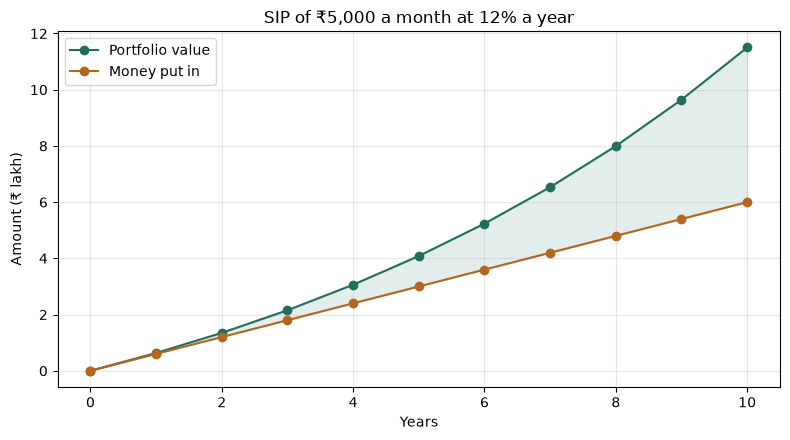

Year  1: value       ₹63,412.52   invested       ₹60,000.00
Year  5: value     ₹4,08,348.35   invested     ₹3,00,000.00
Year 10: value    ₹11,50,193.45   invested     ₹6,00,000.00


In [24]:
import numpy as np
import matplotlib.pyplot as plt
from finance_core import sip_future_value, inr

os.makedirs("charts", exist_ok=True)

monthly, rate, years = 5000, 12, 10
yrs = np.arange(0, years + 1)
value = [sip_future_value(monthly, rate, y) if y else 0 for y in yrs]
invested = [monthly * 12 * y for y in yrs]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(yrs, value, marker="o", color="#1f6f5c", label="Portfolio value")
ax.plot(yrs, invested, marker="o", color="#b5651d", label="Money put in")
ax.fill_between(yrs, invested, value, color="#1f6f5c", alpha=0.12)
ax.set_title("SIP of ₹5,000 a month at 12% a year")
ax.set_xlabel("Years")
ax.set_ylabel("Amount (₹ lakh)")
ax.yaxis.set_major_formatter(lambda x, _: f"{x / 1e5:.0f}")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig("charts/sip_growth.png", dpi=150)
plt.show()

for y in (1, 5, 10):
    print(f"Year {y:>2}: value {inr(value[y]):>16}   invested {inr(invested[y]):>16}")

#### Explanation
The brown line is the money actually paid in, which is a straight line because the instalment never changes. The green line is the portfolio value, and it bends upwards. The shaded area between them is the return. After 1 year the two are close (₹63,412.52 against ₹60,000), after 5 years the value is ₹4,08,348.35 against ₹3,00,000, and after 10 years it is ₹11,50,193.45 against ₹6,00,000. In the second half of the period the gap widens much faster than in the first half, which is compounding at work and the reason for starting early.

## 21. Chart 2: where each EMI payment goes
The EMI stays the same every month, but its split between interest and principal does not. The loan of ₹10 lakh at 9% for 20 years is rolled forward month by month and added up per year.

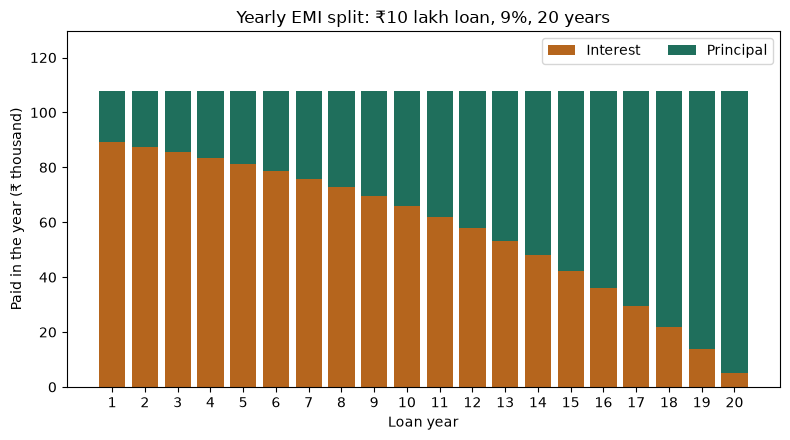

Year 1  interest: ₹89,240.01 | principal: ₹18,727.10
Year 20 interest: ₹5,084.24 | principal: ₹1,02,882.88
Principal exceeds interest from month 149
Balance left after last EMI: 0.0
Total interest: ₹11,59,342.29


In [25]:
from finance_core import emi

loan, rate, years = 1_000_000, 9, 20
r = rate / 12 / 100
payment = emi(loan, rate, years)

balance = loan
interest_by_year, principal_by_year = [], []
crossover = None
month = 0
for yr in range(years):
    interest_sum = principal_sum = 0
    for _ in range(12):
        month += 1
        interest = balance * r
        principal = payment - interest
        balance -= principal
        interest_sum += interest
        principal_sum += principal
        if crossover is None and principal > interest:
            crossover = month
    interest_by_year.append(interest_sum)
    principal_by_year.append(principal_sum)

x = np.arange(1, years + 1)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(x, interest_by_year, color="#b5651d", label="Interest")
ax.bar(x, principal_by_year, bottom=interest_by_year, color="#1f6f5c", label="Principal")
ax.set_title("Yearly EMI split: ₹10 lakh loan, 9%, 20 years")
ax.set_xlabel("Loan year")
ax.set_ylabel("Paid in the year (₹ thousand)")
ax.yaxis.set_major_formatter(lambda v, _: f"{v / 1e3:.0f}")
ax.set_xticks(x)
ax.set_ylim(0, payment * 12 * 1.2)
ax.legend(ncol=2, loc="upper right")
fig.tight_layout()
fig.savefig("charts/emi_split.png", dpi=150)
plt.show()

print("Year 1  interest:", inr(interest_by_year[0]), "| principal:", inr(principal_by_year[0]))
print("Year 20 interest:", inr(interest_by_year[-1]), "| principal:", inr(principal_by_year[-1]))
print("Principal exceeds interest from month", crossover)
print("Balance left after last EMI:", round(balance, 2))
print("Total interest:", inr(sum(interest_by_year)))

#### Explanation
Each bar is one year of payments. The total height is nearly the same every year (12 × ₹8,997.26 ≈ ₹1.08 lakh) but the colours change. In year 1 about ₹89,240 of the payments is interest and only ₹18,727 repays the loan. In year 20 it is the other way round, ₹5,084 interest and ₹1,02,883 principal (the printed values are ₹89,240.01 / ₹18,727.10 and ₹5,084.24 / ₹1,02,882.88). Principal only becomes bigger than interest from month 149, which is in the 13th year. The balance after the last instalment prints as 0.0, and the yearly interest adds up to ₹11,59,342.29, the same total interest as the EMI tool gave. So the simple monthly loop and the closed-form formula agree. The chart also explains why paying a loan off early saves so much: the early payments are mostly interest.

## 22. Chart 3: the 50-30-20 budget

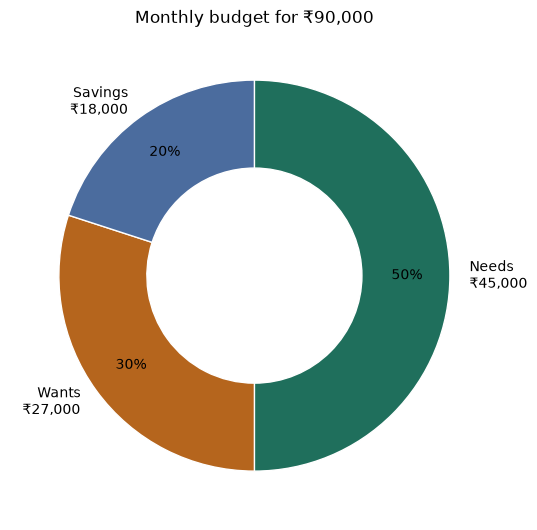

In [26]:
from finance_core import budget_split

income = 90_000
split = budget_split(income)

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.pie(split.values(),
       labels=[f"{k}\n{inr(v, 0)}" for k, v in split.items()],
       colors=["#1f6f5c", "#b5651d", "#4b6c9e"],
       startangle=90, counterclock=False,
       wedgeprops=dict(width=0.45, edgecolor="white"),
       autopct="%1.0f%%", pctdistance=0.78, textprops={"fontsize": 10})
ax.set_title(f"Monthly budget for {inr(income, 0)}")
fig.tight_layout()
fig.savefig("charts/budget_split.png", dpi=150)
plt.show()

#### Explanation
The donut shows the split that `budget_planner` returned for ₹90,000: needs 50% (₹45,000), wants 30% (₹27,000) and savings 20% (₹18,000). The labels carry the rupee amounts and the percentages are inside the ring. The rule is a starting point, not a prescription; someone with a high rent may have needs above 50%, so the numbers are best read as a target to compare against.

## 23. Streamlit app
The last requirement is a front end. The app is a small chat page that sends each question to the same agent used in this notebook and shows the answer together with the tool call that produced it.

In [27]:
%%writefile app.py
"""
FinWise AI — Personal Finance Assistant
Run with: streamlit run app.py

The interface is presentation-focused. Core agent behavior remains in agent_setup.py.
"""
import os
import streamlit as st

from agent_setup import build_agent, run_query

st.set_page_config(
    page_title="FinWise AI | Personal Finance",
    page_icon="₹",
    layout="wide",
    initial_sidebar_state="expanded",
)

EXAMPLES = [
    ("Loan planning", "Calculate EMI for ₹10 lakh loan at 8% interest for 20 years"),
    ("Investment growth", "If I invest ₹7000 monthly for 15 years at 10% return"),
    ("Monthly budget", "Create a budget plan for income ₹90,000"),
    ("Quick calculation", "What is 20% of ₹85,000"),
    ("SIP estimate", "How much will I get if I invest ₹3000 per month for 5 years at 8% return"),
    ("Savings goal", "How much should I save monthly to reach ₹20 lakh in 10 years?"),
]

# Load configured API keys from Streamlit secrets, falling back to environment variables.
secrets_loaded = False
for key_name in ("GOOGLE_API_KEY", "OPENAI_API_KEY"):
    try:
        secret_value = st.secrets.get(key_name)
    except Exception:
        secret_value = None
    if secret_value:
        os.environ[key_name] = secret_value
        secrets_loaded = True

# Google's library warns when both GEMINI_API_KEY and GOOGLE_API_KEY are set, so drop the former.
os.environ.pop("GEMINI_API_KEY", None)

def friendly_error(err):
    """Short, readable reason for a failed request. The raw text is shown separately."""
    text = str(err)
    if "429" in text or "RESOURCE_EXHAUSTED" in text:
        return "The AI service's free daily quota has been used up. Try again after it resets, or use another API key."
    if "503" in text or "UNAVAILABLE" in text:
        return "The AI service is busy right now. Wait a minute and ask again."
    if any(w in text for w in ("API key", "credentials", "PERMISSION_DENIED", "401", "403")):
        return "The API key is missing or was rejected. Check .streamlit/secrets.toml."
    return "Something went wrong while answering."


def show_answer(turn):
    """Draw one assistant reply: the answer or the error, plus the tools that were used."""
    if turn.get("error"):
        st.error(turn["answer"])
        with st.expander("Technical details"):
            st.code(turn["error"])
        return
    st.markdown(turn["answer"])
    if turn.get("tools"):
        with st.expander("View calculation tools used"):
            for tool_name, args in turn["tools"]:
                formatted_args = ", ".join(f"{name}={value}" for name, value in args.items())
                st.code(f"{tool_name}({formatted_args})", language="python")


if "history" not in st.session_state:
    st.session_state.history = []
if "pending_question" not in st.session_state:
    st.session_state.pending_question = ""

st.markdown(
    """
    <style>
    :root { --fw-green: #176b52; --fw-deep: #123d32; --fw-mint: #e9f4ee;
            --fw-ink: #1e2b27; --fw-muted: #66736d; --fw-line: #dce5df; }
    .stApp { background: #f6f8f6; color: var(--fw-ink); }
    [data-testid="stHeader"] { background: rgba(246,248,246,.92); }
    [data-testid="stSidebar"] { background: #eef3ef; border-right: 1px solid var(--fw-line); }
    [data-testid="stSidebar"] [data-testid="stMarkdownContainer"] p { color: #43534b; }
    .hero {
        padding: 1.7rem 1.9rem; border-radius: 18px;
        background: linear-gradient(115deg, #123d32 0%, #176b52 70%, #2e8063 100%);
        color: #fff; margin: .35rem 0 1.25rem 0;
        box-shadow: 0 10px 26px rgba(18,61,50,.12);
    }
    .hero-kicker { font-size: .76rem; text-transform: uppercase; letter-spacing: .16em;
                   color: #c6e5d5; font-weight: 700; margin-bottom: .55rem; }
    .hero h1 { color: #fff; font-size: clamp(1.9rem, 4vw, 2.65rem); line-height: 1.12;
               letter-spacing: -.035em; margin: 0 0 .65rem 0; }
    .hero p { color: #e0eee7; max-width: 760px; margin: 0; font-size: 1rem; }
    .section-label { color: var(--fw-green); font-size: .76rem; font-weight: 800;
                     text-transform: uppercase; letter-spacing: .12em; margin-bottom: .25rem; }
    .panel {
        background: #fff; border: 1px solid var(--fw-line); border-radius: 14px;
        padding: 1rem 1.1rem; margin: .35rem 0 .8rem 0;
    }
    .panel-title { font-weight: 750; color: var(--fw-ink); margin-bottom: .25rem; }
    .muted { color: var(--fw-muted); font-size: .9rem; }
    div.stButton > button {
        border-radius: 9px; border: 1px solid #d4e1d8; min-height: 2.6rem;
        font-weight: 600; transition: all .15s ease;
    }
    div.stButton > button:hover { border-color: var(--fw-green); color: var(--fw-green); }
    div[data-testid="stChatMessage"] { border: 1px solid #e2e9e4; border-radius: 14px;
                                      padding: .85rem 1rem; background: #fff; }
    [data-testid="stChatInput"] { border-color: #cbd9d0; }
    .footer { color: #718078; font-size: .78rem; text-align: center;
              padding: 1.3rem 0 .4rem 0; }
    @media (max-width: 700px) {
        .hero { padding: 1.25rem; border-radius: 14px; }
    }
    </style>
    """,
    unsafe_allow_html=True,
)

with st.sidebar:
    st.markdown("## 🌿 FinWise AI")
    st.caption("Your personal finance workspace")
    st.divider()

    with st.expander("Configuration", expanded=not secrets_loaded):
        if secrets_loaded:
            st.success("API key loaded from Streamlit secrets.")
        else:
            st.caption("Enter your provider key, or configure it in `.streamlit/secrets.toml`.")
            entered_key = st.text_input(
                "Google API key",
                type="password",
                key="google_api_key_input",
                help="The key is used for this app session. Avoid sharing it.",
            )
            if entered_key.strip():
                os.environ["GOOGLE_API_KEY"] = entered_key.strip()

    st.markdown("### Start with a question")
    st.caption("Choose a prompt to send it to the assistant.")
    for index, (label, prompt) in enumerate(EXAMPLES):
        if st.button(label, key=f"example_{index}", use_container_width=True):
            st.session_state.pending_question = prompt

    st.divider()
    left, right = st.columns(2)
    with left:
        st.metric("Questions", len(st.session_state.history))
    with right:
        if st.button("Clear chat", use_container_width=True):
            st.session_state.history = []
            st.session_state.pending_question = ""
            st.rerun()

@st.cache_resource(show_spinner=False)
def get_agent(api_key_fingerprint):
    # The key fingerprint is a cache argument so changing keys refreshes the agent.
    return build_agent()

key_fingerprint = (
    os.getenv("GOOGLE_API_KEY", "") + "|" + os.getenv("OPENAI_API_KEY", "")
)
agent, model_label = get_agent(key_fingerprint)

st.markdown(
    """
    <section class="hero">
      <div class="hero-kicker">Personal finance • Simplified</div>
      <h1>Make your next money decision<br>with more confidence.</h1>
      <p>Explore loan repayments, SIP projections, savings goals and monthly budgets
      with an AI assistant that can use calculation tools to work through your questions.</p>
    </section>
    """,
    unsafe_allow_html=True,
)

offline = "offline" in model_label
status_text = "● Demo mode" if offline else "● Ready to help"
meta_col, info_col = st.columns([1, 2])
with meta_col:
    st.markdown(
        f'<div class="panel"><div class="section-label">Assistant status</div>'
        f'<div class="panel-title">{status_text}</div>'
        f'<div class="muted">Model: {model_label}</div></div>',
        unsafe_allow_html=True,
    )
with info_col:
    st.markdown(
        '<div class="panel"><div class="section-label">What you can do</div>'
        '<div class="panel-title">Plan · Calculate · Compare</div>'
        '<div class="muted">Ask a question in your own words, or choose a suggested prompt '
        'from the sidebar to get started.</div></div>',
        unsafe_allow_html=True,
    )

st.markdown('<div class="section-label">Your conversation</div>', unsafe_allow_html=True)

for turn in st.session_state.history:
    with st.chat_message("user"):
        st.write(turn["question"])
    with st.chat_message("assistant"):
        show_answer(turn)

question = st.chat_input("Ask about an EMI, SIP, budget or savings goal…")
if not question and st.session_state.pending_question:
    question = st.session_state.pending_question
    st.session_state.pending_question = ""

if question:
    with st.chat_message("user"):
        st.write(question)
    with st.chat_message("assistant"):
        with st.spinner("Working through your question…"):
            try:
                result = run_query(agent, question)
                turn = {"question": question,
                        "answer": result.get("answer") or "I couldn't generate an answer for that question.",
                        "tools": result.get("tools_used", [])}
            except Exception as err:
                turn = {"question": question, "answer": friendly_error(err),
                        "tools": [], "error": str(err)[:800]}
        show_answer(turn)

    st.session_state.history.append(turn)
    st.rerun()

st.markdown(
    '<div class="footer">FinWise AI provides educational estimates, not personalized '
    'financial, tax or investment advice. Verify assumptions before making financial decisions.</div>',
    unsafe_allow_html=True,
)

Overwriting app.py


In [ ]:
%%writefile requirements.txt
langchain>=1.0
langchain-core
langchain-google-genai
langchain-openai
streamlit
matplotlib
numpy-financial
pandas

Writing requirements.txt


#### Explanation
Two files are written: `app.py` and `requirements.txt`. The app imports `build_agent` and `run_query` from `agent_setup.py`, so the notebook and the web page cannot drift apart. Its main parts are:

- **API key.** It is read from `st.secrets` (`.streamlit/secrets.toml`). If no key is found, a password-style box in the sidebar's Configuration section appears instead.
- **Example prompts.** Six buttons in the sidebar, one per kind of question, send a ready-made question to the assistant.
- **Agent cache.** `st.cache_resource` builds the agent once instead of on every click, and rebuilds it when the key changes.
- **Chat history.** `st.session_state` keeps the conversation between reruns, and a counter in the sidebar shows how many questions have been asked.
- **`show_answer()`.** One function draws every reply, both the live one and the ones from the history: the answer, and an expander that lists the tool calls. Showing the tool calls makes the tool selection visible to the person using the app.
- **Error handling.** If the agent call fails, `friendly_error()` turns a quota (429), overload (503) or key problem into one plain sentence and the raw error is kept in a "Technical details" expander, so the real cause is never hidden.
- **Status panel.** It reads "Ready to help" with a live model and "Demo mode" when the app runs on the offline test model.
- **Styling.** A single CSS block sets the colours, the header banner and the card look. It does not touch the logic.

To run it locally: `pip install -r requirements.txt` and then `streamlit run app.py`. Put `GOOGLE_API_KEY = "your-key"` in `.streamlit/secrets.toml` and keep that file out of Git. For a public link the app can be deployed on Streamlit Community Cloud, pasting the same line into the app's Secrets setting.

## 24. Testing the app without opening a browser
Streamlit ships a test runner that executes the script headlessly. It is used here to confirm that the page loads, that a question gets answered, and that a failed request shows a readable error instead of crashing. The test runs on the offline test model, so it uses no API quota.

In [ ]:
import logging
logging.getLogger("streamlit").setLevel(logging.ERROR)
from streamlit.testing.v1 import AppTest
import agent_setup

def new_test():
    at = AppTest.from_file(os.path.abspath("app.py"), default_timeout=60)
    at.secrets["GOOGLE_API_KEY"] = ""      # ignore secrets.toml for this test
    at.secrets["OPENAI_API_KEY"] = ""
    return at

# Offline run: the keys are taken out of the environment for the duration of the cell.
saved = {k: os.environ.pop(k, None) for k in ("GOOGLE_API_KEY", "GEMINI_API_KEY", "OPENAI_API_KEY")}
real_run_query = agent_setup.run_query
try:
    at = new_test().run()
    print("Errors on first load :", len(at.exception))
    panel = [m.value for m in at.markdown if "Model:" in m.value][0]
    print("Model line           :", panel.split("Model: ")[1].split("<")[0])

    at.chat_input[0].set_value("Create a budget plan for income ₹90,000").run()
    print("Errors after a query :", len(at.exception))
    print("Chat answer          :")
    print([m.value for m in at.markdown if "Monthly income" in m.value][0])
    print("Expanders            :", [e.label for e in at.expander])

    # failure path: pretend Google is overloaded
    def overloaded(*args, **kwargs):
        raise RuntimeError("503 UNAVAILABLE. This model is currently experiencing high demand.")
    agent_setup.run_query = overloaded
    bad = new_test().run()
    bad.chat_input[0].set_value("anything").run()
    print("\nSimulated 503 -> app crashed:", len(bad.exception) > 0)
    print("Message shown        :", bad.error[0].value)
finally:
    agent_setup.run_query = real_run_query
    for k, v in saved.items():
        if v:
            os.environ[k] = v

Errors on first load : 0
Model line           : offline test model (no API key found)
Errors after a query : 0
Chat answer          :
Monthly income: ₹90,000.00 (50-30-20 rule)
Needs (50%): ₹45,000.00
Wants (30%): ₹27,000.00
Savings (20%): ₹18,000.00
Expanders            : ['View calculation tools used', 'Configuration']



Simulated 503 -> app crashed: False
Message shown        : The AI service is busy right now. Wait a minute and ask again.


#### Explanation
The app loaded with zero errors, and the model line shows the offline test model because the keys are taken out of the environment for this cell. After the budget question was sent through the chat box there were still no errors, the answer shows the 50-30-20 split for ₹90,000, and the page has two expanders: "View calculation tools used" under the answer and "Configuration" in the sidebar.

The last two lines simulate Google being overloaded by making `run_query` raise a 503. The page does not crash. It shows the plain sentence from `friendly_error()` instead, and the raw error would sit in a "Technical details" expander. A harmless `ScriptRunContext` warning can appear on stderr because the script is run outside `streamlit run`. This is a smoke test, not a visual check: it shows that the page and the agent are wired together properly, and looking at the real page with `streamlit run app.py`, which uses your Gemini key, is still the final step.

## 25. Summary and limitations
**What was built.** A LangChain agent with five tools (calculator, EMI, SIP, goal-based SIP and 50-30-20 budget), a system prompt that forces tool use for all arithmetic, nine demonstration queries plus an out-of-scope one, three charts and a Streamlit chat app.

**What the results show.** Every number the agent returned matches the direct tool calls and, where possible, an independent library. The tool selection was correct for all ten questions.

**Limitations.**
- The SIP formula follows the brief and assumes the instalment is paid at the end of each month. If it is paid at the start, the value is higher by a factor of (1 + r).
- Returns are treated as fixed and guaranteed. Real investments fluctuate, and no tax, inflation or expense ratio is included.
- The EMI tool assumes a fixed interest rate and does not model part-prepayments or floating rates.
- The budget tool applies the 50-30-20 rule mechanically.
- The agent answers in this notebook come from Google Gemini (the model name is printed in section 11). The free tier allows only about 20 requests a day per model and each question uses two, so a full run has to be spread over time or run on a project with a higher quota. The tool results do not depend on the model; the wording around them does, and the model sometimes rounds the figures or adds general tips of its own.

**Possible extensions.** Prepayment and step-up SIP tools, an inflation-adjusted goal calculator, conversation memory, and reading the user's actual expenses from a CSV.